### Validação de Clusters: Método do Cotovelo e Silhouette Score


In [12]:
from pathlib import Path
import pandas as pd

base_path = Path.cwd().parent
file_path = base_path / "data" / "processed" / "Base_de_Dados_Processada.csv"

df = pd.read_csv(file_path)

df.head()

,População_2022,Pontuação Indice ODS 2025,Goal 1 Score,Goal 2 Score,Goal 3 Score,Goal 5 Score,Goal 6 Score,Goal 7 Score,Goal 8 Score,Goal 9 Score,...,SDG16_CRP,Normalizado (0-100): SDG16_CRP,SDG16_DRTHMN,Normalizado (0-100): SDG16_DRTHMN,SDG16_TRANSP,Normalizado (0-100): SDG16_TRANSP,SDG17_1_INVST_PB,Normalizado (0-100): SDG17_1_INVST_PB,SDG17_3_P_RC_TRB,Normalizado (0-100): SDG17_3_P_RC_TRB
0,21495.0,41.885064,53.769451,53.255278,66.451721,58.730307,20.177142,56.309444,46.940699,11.631238,...,85.714,85.714,42.857,42.857,66.667,66.667,13.216,0.000000,5.257,8.108054
1,96833.0,45.475390,54.219225,50.890756,65.677811,41.654565,72.408554,68.007222,49.281375,14.603964,...,85.714,85.714,57.143,57.143,66.667,66.667,85.642,1.133196,18.394,34.298246
2,5363.0,47.569518,49.228293,43.817398,89.494428,48.938353,44.025511,63.241944,54.613778,7.181381,...,85.714,85.714,42.857,42.857,66.667,66.667,909.852,38.715329,5.686,8.963317
3,86895.0,48.582323,50.752090,51.083977,73.026011,47.023041,66.630268,69.962222,45.581682,17.049953,...,85.714,85.714,57.143,57.143,50.000,50.000,328.073,12.187507,21.627,40.743620
4,15890.0,48.718897,56.552994,50.268036,79.958615,32.086768,65.794541,68.762222,52.890151,11.397874,...,100.000,100.000,42.857,42.857,66.667,66.667,246.352,8.461212,12.178,21.905901


Retirando as variáveis alvo

In [ ]:
target_col_ideb_af = 'Normalizado (0-100): SDG4_15_IDEB_AF',
target_col_ideb_ai = 'Normalizado (0-100): SDG4_16_IDEB_AI'

targets = df[[target_col_ideb_af, target_col_ideb_ai]].copy()
df = df.drop(columns=[target_col_ideb_af, target_col_ideb_ai])

Definição do intervalo do número `k` e looping para testar melhor possibilidade de valor para a variável

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

k_range = range(2, 11)
inercia = []
silhouette_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    
    inercia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, cluster_labels))

Visualização, método do cotovelo e silhouette score

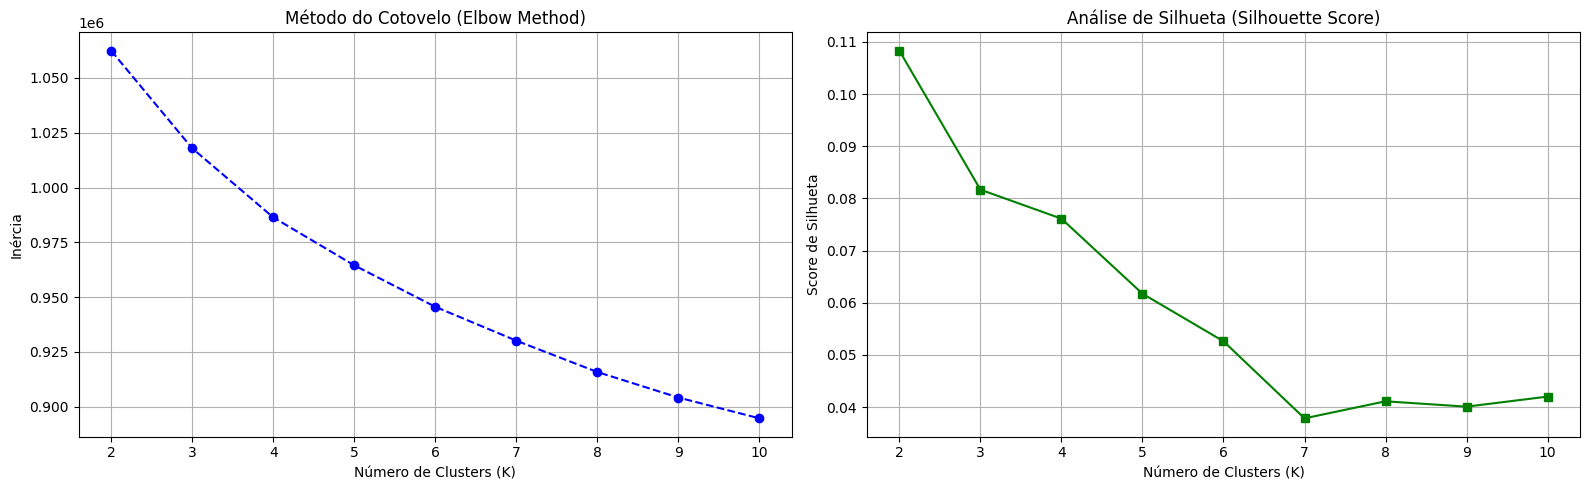

In [15]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

ax1.plot(k_range, inercia, marker='o', linestyle='--', color='b')
ax1.set_title('Método do Cotovelo (Elbow Method)')
ax1.set_xlabel('Número de Clusters (K)')
ax1.set_ylabel('Inércia')
ax1.grid(True)

ax2.plot(k_range, silhouette_scores, marker='s', linestyle='-', color='g')
ax2.set_title('Análise de Silhueta (Silhouette Score)')
ax2.set_xlabel('Número de Clusters (K)')
ax2.set_ylabel('Score de Silhueta')
ax2.grid(True)

plt.tight_layout()
plt.show()


### De acordo com análise de silhueta número de $k$ definido é 7 

Agrupamento por perfil de município 

In [16]:
from sklearn.impute import SimpleImputer

features_perfil = ['SDG1_1_P_F_CU', 'SDG17_3_P_RC_TRB', 'SDG15_2_FLOR', 'SDG5_7_JV_NENT', 'SDG16_3_M_ARM_FG']

X_perfil = df[features_perfil].copy()

imputer_perfil = SimpleImputer(strategy='median')
X_perfil_imputed = pd.DataFrame(imputer_perfil.fit_transform(X_perfil), columns=features_perfil)

scaler_perfil = StandardScaler()
X_perfil_scaled = scaler_perfil.fit_transform(X_perfil_imputed)

n_perfis = 7
kmeans_perfil = KMeans(n_clusters=n_perfis, random_state=42, n_init=10)
labels_perfil = kmeans_perfil.fit_predict(X_perfil_scaled)

df['Cluster_Perfil'] = labels_perfil

Análise da média de cada variável por cluster

In [17]:
df_analise_perfis = X_perfil_imputed.copy()
df_analise_perfis['Cluster'] = labels_perfil

resumo_perfis = df_analise_perfis.groupby('Cluster').mean().round(2)
display(resumo_perfis)

,SDG1_1_P_F_CU,SDG17_3_P_RC_TRB,SDG15_2_FLOR,SDG5_7_JV_NENT,SDG16_3_M_ARM_FG
Cluster,,,,,
0,73.97,4.46,6.29,12.38,9.30
1,58.98,7.65,4.87,21.50,6.82
2,49.23,7.81,2.17,7.86,5.53
3,59.59,22.32,1.58,11.58,10.43
4,79.09,2.75,518.24,10.06,3.28
5,70.14,5.93,3.54,15.55,47.79
6,71.14,6.38,134.75,16.25,16.40


Mapemento de perfis por nomes

In [ ]:
nomes_perfis_pca = {
    0: 'Vulnerabilidade Tradicional',
    1: 'Alta Exclusão da Juventude e Gênero',
    2: 'Alto Desenvolvimento Social',
    3: 'Alta Arrecadação (Enclaves/Metrópoles)',
    4: 'Regiões Florestais (Extrema Vulnerabilidade)',
    5: 'Zonas de Alta Violência Letal',
    6: 'Fronteiras Agrícolas (Transição Florestal)'
}

df['Nome_Perfil'] = df['Cluster_Perfil'].map(nomes_perfis_pca)

display(df['Nome_Perfil'].value_counts())

Nome_Perfil
Vulnerabilidade Tradicional                     1645
Alta Exclusão da Juventude e Gênero             1338
Alto Desenvolvimento Social                     1112
Zonas de Alta Violência Letal                    756
Alta Arrecadação (Enclaves/Metrópoles)           642
Fronteiras Agrícolas (Transição Florestal)        72
Regiões Florestais (Extrema Vulnerabilidade)       5
Name: count, dtype: int64

Adicionando o perfil do município na base de dados processada

In [19]:
file_path = base_path / "data" / "raw" / "Base_de_Dados_IDSC-BR_2025.xlsx"

df_nomes = pd.read_excel(file_path, 
                         sheet_name='Todos os Dados', 
                         usecols=['Município', 'UF', target_col_ideb_af, target_col_ideb_ai])

df_com_nomes = df.join(df_nomes)

Visualização de Municípios

In [20]:
municipios_vulneraveis = df_com_nomes[df_com_nomes['Nome_Perfil'] == 'Vulnerabilidade Tradicional']

# Exibe os 10 primeiros municípios deste grupo
display(municipios_vulneraveis[['Município', 'UF', 'Nome_Perfil', target_col_ideb_af, target_col_ideb_ai]].head(10))

desenvolvimento_social = df_com_nomes[df_com_nomes['Nome_Perfil'] == 'Alto Desenvolvimento Social']
display(desenvolvimento_social[['Município', 'UF', 'Nome_Perfil']].head(10))

,Município,UF,Nome_Perfil,SDG4_15_IDEB_AF,SDG4_16_IDEB_AI
7,Costa Marques,RO,Vulnerabilidade Tradicional,NaN,4.4
9,Guajará-Mirim,RO,Vulnerabilidade Tradicional,NaN,4.6
53,Assis Brasil,AC,Vulnerabilidade Tradicional,NaN,5.1
57,Cruzeiro do Sul,AC,Vulnerabilidade Tradicional,4.4,4.8
58,Epitaciolândia,AC,Vulnerabilidade Tradicional,NaN,6.2
59,Feijó,AC,Vulnerabilidade Tradicional,NaN,4.7
60,Jordão,AC,Vulnerabilidade Tradicional,4.9,4.4
61,Mâncio Lima,AC,Vulnerabilidade Tradicional,NaN,4.8
63,Marechal Thaumaturgo,AC,Vulnerabilidade Tradicional,3.6,4.1
64,Plácido de Castro,AC,Vulnerabilidade Tradicional,3.6,5.1


,Município,UF,Nome_Perfil
0,Alta Floresta D'Oeste,RO,Alto Desenvolvimento Social
6,Corumbiara,RO,Alto Desenvolvimento Social
14,Ouro Preto do Oeste,RO,Alto Desenvolvimento Social
17,Presidente Médici,RO,Alto Desenvolvimento Social
19,Rolim de Moura,RO,Alto Desenvolvimento Social
22,São Miguel do Guaporé,RO,Alto Desenvolvimento Social
28,Novo Horizonte do Oeste,RO,Alto Desenvolvimento Social
311,Abreulândia,TO,Alto Desenvolvimento Social
321,Araguaçu,TO,Alto Desenvolvimento Social
326,Arraias,TO,Alto Desenvolvimento Social
